# Fixed-Income Market Risk Analysis Using Python

## Project Overview

This project analyzes historical US Treasury par yield curve movements from 2020 to 2025 and examines their implications for a hypothetical fixed-income portfolio.

## Business Objective

The objective is to understand interest-rate risk across different Treasury maturities, estimate portfolio sensitivity to yield movements, and measure historical downside risk using Value at Risk (VaR) and Expected Shortfall (ES).

## Tools Used

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## Scope

The analysis covers data preparation, yield trends, daily yield changes, volatility, correlations, duration, DV01, historical P&L estimates, VaR, Expected Shortfall, and a comparison of DV01 estimates with cash-flow repricing.

## Important Limitation

The portfolio is hypothetical. Treasury par yields are used as simplified yield proxies for bond valuation; therefore, the results are illustrative risk estimates rather than actual market prices or trading P&L.

In [1]:
print("Treasury Market Risk Project")

Treasury Market Risk Project


## 1. Data Loading and Preparation

Load the Treasury yield datasets, standardize column names, combine the files, convert dates into datetime format, and sort observations chronologically before analysis.

In [2]:
import pandas as pd

In [3]:
df_2020_2023 = pd.read_csv("par-yield-curve-rates-2020-2023.csv")

df_2020_2023.head()

,date,1 mo,2 mo,3 mo,4 mo,6 mo,1 yr,2 yr,3 yr,5 yr,7 yr,10 yr,20 yr,30 yr
0,01/02/2020,1.53,1.55,1.54,NaN,1.57,1.56,1.58,1.59,1.67,1.79,1.88,2.19,2.33
1,01/03/2020,1.52,1.55,1.52,NaN,1.55,1.55,1.53,1.54,1.59,1.71,1.80,2.11,2.26
2,01/06/2020,1.54,1.54,1.56,NaN,1.56,1.54,1.54,1.56,1.61,1.72,1.81,2.13,2.28
3,01/07/2020,1.52,1.53,1.54,NaN,1.56,1.53,1.54,1.55,1.62,1.74,1.83,2.16,2.31
4,01/08/2020,1.50,1.53,1.54,NaN,1.56,1.55,1.58,1.61,1.67,1.78,1.87,2.21,2.35


In [4]:
df_2020_2023.shape

(1001, 14)

In [5]:
df_2024 = pd.read_csv("daily-treasury-rates_2024.csv")

df_2024.head()

,Date,1 Mo,2 Mo,3 Mo,4 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr
0,12/31/2024,4.40,4.39,4.37,4.32,4.24,4.16,4.25,4.27,4.38,4.48,4.58,4.86,4.78
1,12/30/2024,4.43,4.42,4.37,4.33,4.25,4.17,4.24,4.29,4.37,4.46,4.55,4.84,4.77
2,12/27/2024,4.44,4.43,4.31,4.35,4.29,4.20,4.31,4.36,4.45,4.53,4.62,4.89,4.82
3,12/26/2024,4.45,4.45,4.35,4.37,4.31,4.23,4.30,4.35,4.42,4.49,4.58,4.83,4.76
4,12/24/2024,4.44,4.44,4.40,4.38,4.30,4.24,4.29,4.36,4.43,4.52,4.59,4.84,4.76


In [6]:
df_2024.shape

(250, 14)

In [7]:
df_2025 = pd.read_csv("daily-treasury-rates_2025.csv")

df_2025.head()

,Date,1 Mo,1.5 Month,2 Mo,3 Mo,4 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr
0,12/31/2025,3.74,3.75,3.67,3.67,3.63,3.59,3.48,3.47,3.55,3.73,3.94,4.18,4.79,4.84
1,12/30/2025,3.65,3.71,3.65,3.65,3.63,3.59,3.47,3.45,3.50,3.68,3.89,4.14,4.76,4.81
2,12/29/2025,3.69,3.70,3.70,3.68,3.66,3.59,3.48,3.45,3.51,3.67,3.88,4.12,4.75,4.80
3,12/26/2025,3.70,3.69,3.72,3.64,3.66,3.58,3.49,3.46,3.54,3.68,3.89,4.14,4.76,4.81
4,12/24/2025,3.72,3.73,3.74,3.69,3.67,3.59,3.50,3.47,3.56,3.70,3.91,4.15,4.75,4.79


In [8]:
df_2025.shape

(249, 15)

In [9]:
df_2020_2023.columns = df_2020_2023.columns.str.strip().str.lower()
df_2024.columns = df_2024.columns.str.strip().str.lower()
df_2025.columns = df_2025.columns.str.strip().str.lower()

df_2025.columns

Index(['date', '1 mo', '1.5 month', '2 mo', '3 mo', '4 mo', '6 mo', '1 yr',
       '2 yr', '3 yr', '5 yr', '7 yr', '10 yr', '20 yr', '30 yr'],
      dtype='str')

In [10]:
print("2020–2023 columns:")
print(df_2020_2023.columns.tolist())

print("\n2024 columns:")
print(df_2024.columns.tolist())

print("\n2025 columns:")
print(df_2025.columns.tolist())

2020–2023 columns:
['date', '1 mo', '2 mo', '3 mo', '4 mo', '6 mo', '1 yr', '2 yr', '3 yr', '5 yr', '7 yr', '10 yr', '20 yr', '30 yr']

2024 columns:
['date', '1 mo', '2 mo', '3 mo', '4 mo', '6 mo', '1 yr', '2 yr', '3 yr', '5 yr', '7 yr', '10 yr', '20 yr', '30 yr']

2025 columns:
['date', '1 mo', '1.5 month', '2 mo', '3 mo', '4 mo', '6 mo', '1 yr', '2 yr', '3 yr', '5 yr', '7 yr', '10 yr', '20 yr', '30 yr']


In [11]:
df_treasury = pd.concat(
    [df_2020_2023, df_2024, df_2025],
    ignore_index=True
)

df_treasury.shape

(1500, 15)

In [13]:
df_treasury["date"] = pd.to_datetime(
    df_treasury["date"],
    format="mixed",
    dayfirst=False
)

df_treasury["date"].dtype

dtype('<M8[us]')

In [14]:
df_treasury = df_treasury.sort_values("date").reset_index(drop=True)

df_treasury.head()

,date,1 mo,2 mo,3 mo,4 mo,6 mo,1 yr,2 yr,3 yr,5 yr,7 yr,10 yr,20 yr,30 yr,1.5 month
0,2020-01-02,1.53,1.55,1.54,NaN,1.57,1.56,1.58,1.59,1.67,1.79,1.88,2.19,2.33,NaN
1,2020-01-03,1.52,1.55,1.52,NaN,1.55,1.55,1.53,1.54,1.59,1.71,1.80,2.11,2.26,NaN
2,2020-01-06,1.54,1.54,1.56,NaN,1.56,1.54,1.54,1.56,1.61,1.72,1.81,2.13,2.28,NaN
3,2020-01-07,1.52,1.53,1.54,NaN,1.56,1.53,1.54,1.55,1.62,1.74,1.83,2.16,2.31,NaN
4,2020-01-08,1.50,1.53,1.54,NaN,1.56,1.55,1.58,1.61,1.67,1.78,1.87,2.21,2.35,NaN


In [15]:
print("First date:", df_treasury["date"].min())
print("Last date:", df_treasury["date"].max())
print("Total rows:", len(df_treasury))
print("Duplicate dates:", df_treasury["date"].duplicated().sum())

First date: 2020-01-02 00:00:00
Last date: 2025-12-31 00:00:00
Total rows: 1500
Duplicate dates: 0


In [16]:
df_treasury.isnull().sum()

date            0
1 mo            0
2 mo            0
3 mo            0
4 mo          701
6 mo            0
1 yr            0
2 yr            0
3 yr            0
5 yr            0
7 yr            0
10 yr           0
20 yr           0
30 yr           0
1.5 month    1282
dtype: int64

## 2. Treasury Yield Analysis

Analyze historical Treasury yields across the 2-year, 5-year, 10-year, and 30-year maturities. Examine yield trends, daily changes, volatility, and correlations to understand how interest rates moved over the sample period.

In [17]:
key_maturities = ["2 yr", "5 yr", "10 yr", "30 yr"]

df_treasury[key_maturities].describe()

,2 yr,5 yr,10 yr,30 yr
count,1500.000000,1500.000000,1500.000000,1500.000000
mean,2.730393,2.745927,2.954527,3.331187
std,1.862476,1.570450,1.407122,1.252004
min,0.090000,0.190000,0.520000,0.990000
25%,0.270000,0.880000,1.540000,2.067500
50%,3.590000,3.595000,3.570000,3.730000
75%,4.300000,4.060000,4.202500,4.500000
max,5.190000,4.950000,4.980000,5.110000


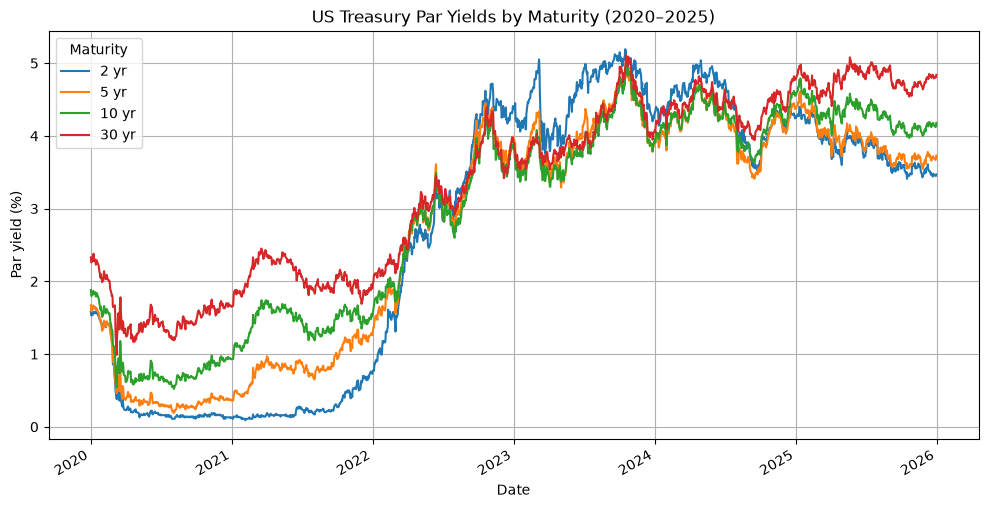

In [18]:
import matplotlib.pyplot as plt

df_treasury.plot(
    x="date",
    y=key_maturities,
    figsize=(12, 6)
)

plt.title("US Treasury Par Yields by Maturity (2020–2025)")
plt.xlabel("Date")
plt.ylabel("Par yield (%)")
plt.legend(title="Maturity")
plt.grid(True)
plt.show()

In [19]:
for maturity in key_maturities:
    df_treasury[f"{maturity}_change"] = df_treasury[maturity].diff()

df_treasury[
    ["date", "2 yr", "2 yr_change",
     "5 yr", "5 yr_change",
     "10 yr", "10 yr_change",
     "30 yr", "30 yr_change"]
].head(10)

,date,2 yr,2 yr_change,5 yr,5 yr_change,10 yr,10 yr_change,30 yr,30 yr_change
0,2020-01-02,1.58,NaN,1.67,NaN,1.88,NaN,2.33,NaN
1,2020-01-03,1.53,-0.05,1.59,-0.08,1.80,-0.08,2.26,-0.07
2,2020-01-06,1.54,0.01,1.61,0.02,1.81,0.01,2.28,0.02
3,2020-01-07,1.54,0.00,1.62,0.01,1.83,0.02,2.31,0.03
4,2020-01-08,1.58,0.04,1.67,0.05,1.87,0.04,2.35,0.04
5,2020-01-09,1.58,0.00,1.65,-0.02,1.85,-0.02,2.38,0.03
6,2020-01-10,1.56,-0.02,1.63,-0.02,1.83,-0.02,2.28,-0.10
7,2020-01-13,1.58,0.02,1.65,0.02,1.85,0.02,2.30,0.02
8,2020-01-14,1.58,0.00,1.63,-0.02,1.82,-0.03,2.27,-0.03
9,2020-01-15,1.56,-0.02,1.60,-0.03,1.79,-0.03,2.23,-0.04


In [20]:
daily_volatility = (
    df_treasury[[f"{maturity}_change" for maturity in key_maturities]]
    .std()
)

daily_volatility

2 yr_change     0.063240
5 yr_change     0.064654
10 yr_change    0.060881
30 yr_change    0.057631
dtype: float64

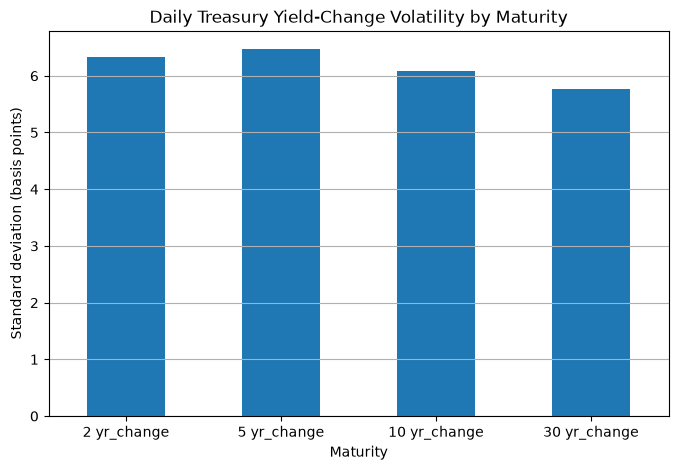

In [21]:
daily_volatility_bps = daily_volatility * 100

daily_volatility_bps.plot(
    kind="bar",
    figsize=(8, 5),
    title="Daily Treasury Yield-Change Volatility by Maturity"
)

plt.xlabel("Maturity")
plt.ylabel("Standard deviation (basis points)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [22]:
yield_changes = df_treasury[
    [f"{maturity}_change" for maturity in key_maturities]
]

yield_correlation = yield_changes.corr()

yield_correlation

,2 yr_change,5 yr_change,10 yr_change,30 yr_change
2 yr_change,1.000000,0.902390,0.762333,0.560438
5 yr_change,0.902390,1.000000,0.931666,0.767658
10 yr_change,0.762333,0.931666,1.000000,0.923852
30 yr_change,0.560438,0.767658,0.923852,1.000000


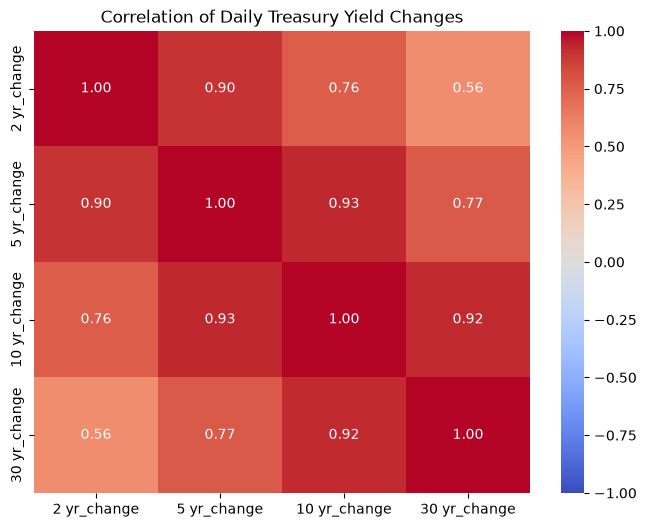

In [23]:
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    yield_correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation of Daily Treasury Yield Changes")
plt.show()

In [24]:
portfolio_value = 1_000_000

portfolio_weights = {
    "2 yr": 0.30,
    "10 yr": 0.40,
    "30 yr": 0.30
}

portfolio_weights

{'2 yr': 0.3, '10 yr': 0.4, '30 yr': 0.3}

In [25]:
valuation_date = df_treasury.iloc[0]

valuation_date[["date", "2 yr", "10 yr", "30 yr"]]

date     2020-01-02 00:00:00
2 yr                    1.58
10 yr                   1.88
30 yr                   2.33
Name: 0, dtype: object

## 3. Hypothetical Portfolio and Market Risk

Construct a hypothetical $1 million Treasury bond portfolio across the 2-year, 10-year, and 30-year maturities. Calculate bond duration and DV01 to estimate interest-rate sensitivity, then evaluate historical P&L, Value at Risk (VaR), and Expected Shortfall using daily yield scenarios.

In [26]:
bond_portfolio = {
    "2 yr": {
        "maturity_years": 2,
        "coupon_rate": 0.0158,
        "weight": 0.30
    },
    "10 yr": {
        "maturity_years": 10,
        "coupon_rate": 0.0188,
        "weight": 0.40
    },
    "30 yr": {
        "maturity_years": 30,
        "coupon_rate": 0.0233,
        "weight": 0.30
    }
}

bond_portfolio

{'2 yr': {'maturity_years': 2, 'coupon_rate': 0.0158, 'weight': 0.3},
 '10 yr': {'maturity_years': 10, 'coupon_rate': 0.0188, 'weight': 0.4},
 '30 yr': {'maturity_years': 30, 'coupon_rate': 0.0233, 'weight': 0.3}}

In [27]:
face_value = 1000

for maturity, details in bond_portfolio.items():
    details["coupon_payment"] = (
        face_value * details["coupon_rate"] / 2
    )

bond_portfolio

{'2 yr': {'maturity_years': 2,
  'coupon_rate': 0.0158,
  'weight': 0.3,
  'coupon_payment': 7.9},
 '10 yr': {'maturity_years': 10,
  'coupon_rate': 0.0188,
  'weight': 0.4,
  'coupon_payment': 9.4},
 '30 yr': {'maturity_years': 30,
  'coupon_rate': 0.0233,
  'weight': 0.3,
  'coupon_payment': 11.65}}

In [28]:
for maturity, details in bond_portfolio.items():
    coupon = details["coupon_payment"]
    periods = details["maturity_years"] * 2
    yield_rate = details["coupon_rate"]
    periodic_yield = yield_rate / 2

    price = (
        coupon * (1 - (1 + periodic_yield) ** (-periods))
        / periodic_yield
        + face_value * (1 + periodic_yield) ** (-periods)
    )

    details["initial_price"] = price

bond_portfolio

{'2 yr': {'maturity_years': 2,
  'coupon_rate': 0.0158,
  'weight': 0.3,
  'coupon_payment': 7.9,
  'initial_price': 1000.0},
 '10 yr': {'maturity_years': 10,
  'coupon_rate': 0.0188,
  'weight': 0.4,
  'coupon_payment': 9.4,
  'initial_price': 1000.0},
 '30 yr': {'maturity_years': 30,
  'coupon_rate': 0.0233,
  'weight': 0.3,
  'coupon_payment': 11.65,
  'initial_price': 1000.0}}

In [29]:
for maturity, details in bond_portfolio.items():
    allocation = portfolio_value * details["weight"]

    details["allocation"] = allocation
    details["units"] = allocation / details["initial_price"]

bond_portfolio

{'2 yr': {'maturity_years': 2,
  'coupon_rate': 0.0158,
  'weight': 0.3,
  'coupon_payment': 7.9,
  'initial_price': 1000.0,
  'allocation': 300000.0,
  'units': 300.0},
 '10 yr': {'maturity_years': 10,
  'coupon_rate': 0.0188,
  'weight': 0.4,
  'coupon_payment': 9.4,
  'initial_price': 1000.0,
  'allocation': 400000.0,
  'units': 400.0},
 '30 yr': {'maturity_years': 30,
  'coupon_rate': 0.0233,
  'weight': 0.3,
  'coupon_payment': 11.65,
  'initial_price': 1000.0,
  'allocation': 300000.0,
  'units': 300.0}}

In [30]:
for maturity, details in bond_portfolio.items():
    coupon = details["coupon_payment"]
    periods = details["maturity_years"] * 2
    yield_rate = details["coupon_rate"]
    periodic_yield = yield_rate / 2

    cash_flows = [coupon] * periods
    cash_flows[-1] += face_value

    times = list(range(1, periods + 1))

    present_values = [
        cash_flows[t - 1] / (1 + periodic_yield) ** t
        for t in times
    ]

    macaulay_duration = sum(
        (t / 2) * pv for t, pv in zip(times, present_values)
    ) / details["initial_price"]

    modified_duration = macaulay_duration / (1 + periodic_yield)

    details["modified_duration"] = modified_duration
    details["dv01_per_bond"] = (
        details["initial_price"] * modified_duration * 0.0001
    )
    details["portfolio_dv01"] = (
        details["dv01_per_bond"] * details["units"]
    )

{
    maturity: {
        "modified_duration": details["modified_duration"],
        "dv01_per_bond": details["dv01_per_bond"],
        "portfolio_dv01": details["portfolio_dv01"]
    }
    for maturity, details in bond_portfolio.items()
}

{'2 yr': {'modified_duration': 1.9611155795997914,
  'dv01_per_bond': 0.19611155795997917,
  'portfolio_dv01': 58.83346738799375},
 '10 yr': {'modified_duration': 9.077519435293592,
  'dv01_per_bond': 0.9077519435293593,
  'portfolio_dv01': 363.1007774117437},
 '30 yr': {'modified_duration': 21.498086962418167,
  'dv01_per_bond': 2.149808696241817,
  'portfolio_dv01': 644.9426088725451}}

In [31]:
total_dv01 = sum(
    details["portfolio_dv01"]
    for details in bond_portfolio.values()
)

for maturity, details in bond_portfolio.items():
    details["dv01_contribution_pct"] = (
        details["portfolio_dv01"] / total_dv01 * 100
    )

{
    maturity: round(details["dv01_contribution_pct"], 2)
    for maturity, details in bond_portfolio.items()
}

{'2 yr': 5.51, '10 yr': 34.03, '30 yr': 60.45}

In [32]:
total_dv01 = sum(
    details["portfolio_dv01"]
    for details in bond_portfolio.values()
)

yield_increase_bps = 1

estimated_pnl = -total_dv01 * yield_increase_bps

print(f"Total portfolio DV01: ${total_dv01:,.2f} per bp")
print(f"Yield increase: {yield_increase_bps} bp")
print(f"Estimated P&L: ${estimated_pnl:,.2f}")

Total portfolio DV01: $1,066.88 per bp
Yield increase: 1 bp
Estimated P&L: $-1,066.88


In [33]:
# Estimate daily portfolio P&L using DV01

for maturity in ["2 yr", "10 yr", "30 yr"]:
    df_treasury[f"{maturity}_pnl"] = (
        -bond_portfolio[maturity]["portfolio_dv01"]
        * df_treasury[f"{maturity}_change_bps"]
    )

df_treasury["portfolio_pnl"] = (
    df_treasury["2 yr_pnl"]
    + df_treasury["10 yr_pnl"]
    + df_treasury["30 yr_pnl"]
)

df_treasury[
    ["date", "2 yr_change_bps", "10 yr_change_bps",
     "30 yr_change_bps", "portfolio_pnl"]
].head(10)

KeyError: '2 yr_change_bps'

In [34]:
df_treasury.columns.tolist()

['date',
 '1 mo',
 '2 mo',
 '3 mo',
 '4 mo',
 '6 mo',
 '1 yr',
 '2 yr',
 '3 yr',
 '5 yr',
 '7 yr',
 '10 yr',
 '20 yr',
 '30 yr',
 '1.5 month',
 '2 yr_change',
 '5 yr_change',
 '10 yr_change',
 '30 yr_change']

In [35]:
# Convert daily yield changes from percentage points to basis points
for maturity in ["2 yr", "10 yr", "30 yr"]:
    df_treasury[f"{maturity}_change_bps"] = (
        df_treasury[f"{maturity}_change"] * 100
    )

# Estimate daily P&L for each bond position using DV01
for maturity in ["2 yr", "10 yr", "30 yr"]:
    df_treasury[f"{maturity}_pnl"] = (
        -bond_portfolio[maturity]["portfolio_dv01"]
        * df_treasury[f"{maturity}_change_bps"]
    )

# Add the P&L across all three positions
df_treasury["portfolio_pnl"] = (
    df_treasury["2 yr_pnl"]
    + df_treasury["10 yr_pnl"]
    + df_treasury["30 yr_pnl"]
)

# Display the first 10 observations
df_treasury[
    [
        "date",
        "2 yr_change_bps",
        "10 yr_change_bps",
        "30 yr_change_bps",
        "portfolio_pnl",
    ]
].head(10)

,date,2 yr_change_bps,10 yr_change_bps,30 yr_change_bps,portfolio_pnl
0,2020-01-02,NaN,NaN,NaN,NaN
1,2020-01-03,-5.0,-8.0,-7.0,7713.571818
2,2020-01-06,1.0,1.0,2.0,-1711.819463
3,2020-01-07,0.0,2.0,3.0,-2661.029381
4,2020-01-08,4.0,4.0,4.0,-4267.507415
5,2020-01-09,0.0,-2.0,3.0,-1208.626272
6,2020-01-10,-2.0,-2.0,-10.0,7293.294578
7,2020-01-13,2.0,2.0,2.0,-2133.753707
8,2020-01-14,0.0,-3.0,-3.0,3024.130159
9,2020-01-15,-2.0,-3.0,-4.0,3786.739703


In [36]:
daily_pnl = df_treasury["portfolio_pnl"].dropna()

print(f"Trading-day observations: {len(daily_pnl)}")
print(f"Average daily P&L: ${daily_pnl.mean():,.2f}")
print(f"Daily P&L standard deviation: ${daily_pnl.std():,.2f}")
print(f"Best estimated day: ${daily_pnl.max():,.2f}")
print(f"Worst estimated day: ${daily_pnl.min():,.2f}")

Trading-day observations: 1499
Average daily P&L: $-171.12
Daily P&L standard deviation: $6,068.41
Best estimated day: $30,539.92
Worst estimated day: $-29,880.43


In [37]:
# Calculate historical daily VaR at 95% confidence
var_95 = -daily_pnl.quantile(0.05)

print(f"95% Historical VaR: ${var_95:,.2f}")

95% Historical VaR: $9,666.29


In [38]:
# Calculate 95% Expected Shortfall

var_threshold = daily_pnl.quantile(0.05)

worst_5_percent = daily_pnl[daily_pnl <= var_threshold]

expected_shortfall_95 = -worst_5_percent.mean()

print(f"95% Historical VaR: ${var_95:,.2f}")
print(f"95% Historical Expected Shortfall: ${expected_shortfall_95:,.2f}")
print(f"Number of tail observations: {len(worst_5_percent)}")

95% Historical VaR: $9,666.29
95% Historical Expected Shortfall: $13,148.41
Number of tail observations: 75


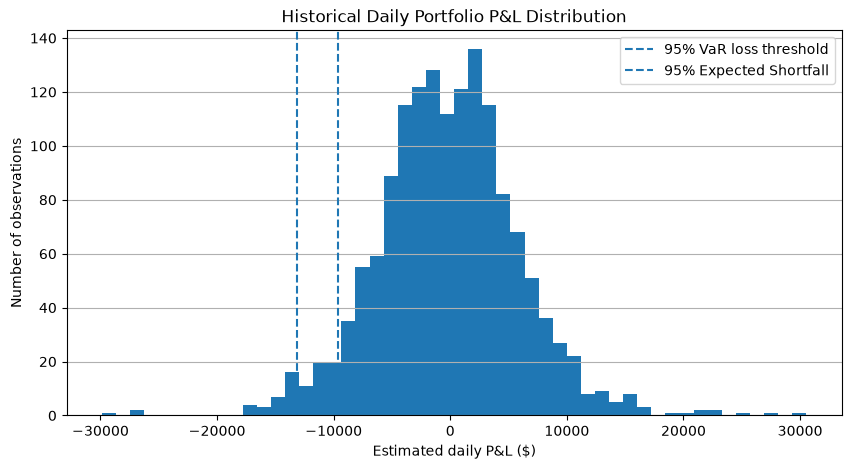

In [39]:
plt.figure(figsize=(10, 5))

plt.hist(daily_pnl, bins=50)

plt.axvline(
    -var_95,
    linestyle="--",
    label="95% VaR loss threshold"
)

plt.axvline(
    -expected_shortfall_95,
    linestyle="--",
    label="95% Expected Shortfall"
)

plt.title("Historical Daily Portfolio P&L Distribution")
plt.xlabel("Estimated daily P&L ($)")
plt.ylabel("Number of observations")
plt.legend()
plt.grid(axis="y")
plt.show()

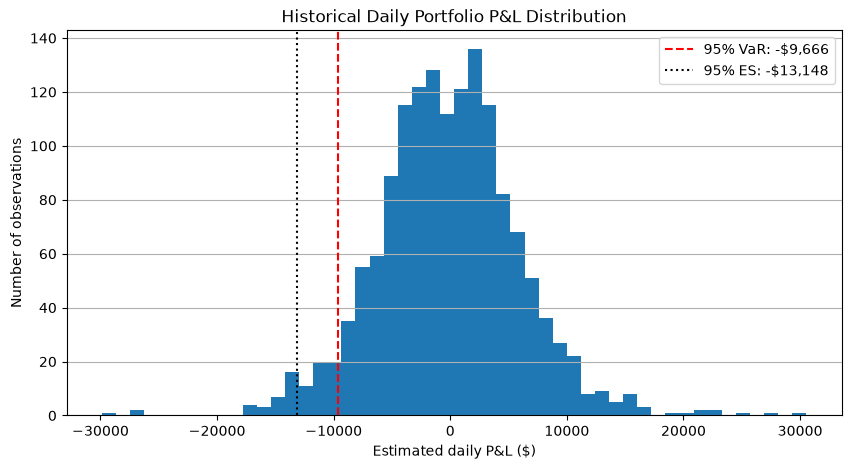

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(daily_pnl, bins=50)

plt.axvline(
    -var_95,
    color="red",
    linestyle="--",
    label=f"95% VaR: -${var_95:,.0f}"
)

plt.axvline(
    -expected_shortfall_95,
    color="black",
    linestyle=":",
    label=f"95% ES: -${expected_shortfall_95:,.0f}"
)

plt.title("Historical Daily Portfolio P&L Distribution")
plt.xlabel("Estimated daily P&L ($)")
plt.ylabel("Number of observations")
plt.legend()
plt.grid(axis="y")
plt.show()

In [41]:
# Identify the five worst estimated P&L days

worst_days = df_treasury.nsmallest(
    5, "portfolio_pnl"
)[
    [
        "date",
        "2 yr_change_bps",
        "10 yr_change_bps",
        "30 yr_change_bps",
        "portfolio_pnl",
    ]
]

worst_days

,date,2 yr_change_bps,10 yr_change_bps,30 yr_change_bps,portfolio_pnl
51,2020-03-17,11.0,29.0,29.0,-29880.426344
46,2020-03-10,12.0,22.0,29.0,-27397.554369
613,2022-06-13,34.0,28.0,22.0,-26355.897054
1069,2024-04-10,23.0,19.0,14.0,-17281.281045
683,2022-09-22,9.0,19.0,15.0,-17102.555110


In [42]:
# Identify the five best estimated P&L days

best_days = df_treasury.nlargest(
    5, "portfolio_pnl"
)[
    [
        "date",
        "2 yr_change_bps",
        "10 yr_change_bps",
        "30 yr_change_bps",
        "portfolio_pnl",
    ]
]

best_days

,date,2 yr_change_bps,10 yr_change_bps,30 yr_change_bps,portfolio_pnl
717,2022-11-10,-27.0,-30.0,-28.0,30539.919990
44,2020-03-06,-10.0,-18.0,-31.0,27117.369542
45,2020-03-09,-11.0,-20.0,-26.0,24677.691520
50,2020-03-16,-13.0,-21.0,-22.0,22578.688797
54,2020-03-20,-7.0,-20.0,-23.0,22507.529824


In [43]:
# Price a bond using semiannual coupon payments
def price_bond(coupon_rate, maturity_years, yield_rate, face_value=1000):
    periods = maturity_years * 2
    coupon = face_value * coupon_rate / 2
    periodic_yield = yield_rate / 2

    cash_flows = [coupon] * periods
    cash_flows[-1] += face_value

    return sum(
        cash_flow / (1 + periodic_yield) ** period
        for period, cash_flow in enumerate(cash_flows, start=1)
    )


# Reprice each bond under each historical daily yield shock
for maturity in ["2 yr", "10 yr", "30 yr"]:
    details = bond_portfolio[maturity]

    # Starting yield, expressed as a decimal
    starting_yield = details["coupon_rate"]

    # Apply historical yield changes to the starting yield
    scenario_yield = (
        starting_yield
        + df_treasury[f"{maturity}_change_bps"] / 10000
    )

    # Calculate scenario bond prices
    scenario_prices = scenario_yield.apply(
        lambda y: price_bond(
            details["coupon_rate"],
            details["maturity_years"],
            y
        ) if pd.notna(y) else float("nan")
    )

    # Convert price changes into position-level P&L
    df_treasury[f"{maturity}_repriced_pnl"] = (
        scenario_prices - details["initial_price"]
    ) * details["units"]


# Combine P&L across the three positions
df_treasury["repriced_portfolio_pnl"] = (
    df_treasury["2 yr_repriced_pnl"]
    + df_treasury["10 yr_repriced_pnl"]
    + df_treasury["30 yr_repriced_pnl"]
)

# Compare the two methods on the first few observations
df_treasury[
    [
        "date",
        "portfolio_pnl",
        "repriced_portfolio_pnl"
    ]
].head(10)

,date,portfolio_pnl,repriced_portfolio_pnl
0,2020-01-02,NaN,NaN
1,2020-01-03,7713.571818,7768.057327
2,2020-01-06,-1711.819463,-1708.186172
3,2020-01-07,-2661.029381,-2652.557928
4,2020-01-08,-4267.507415,-4250.718277
5,2020-01-09,-1208.626272,-1200.153770
6,2020-01-10,7293.294578,7381.128130
7,2020-01-13,-2133.753707,-2129.549295
8,2020-01-14,3024.130159,3033.564951
9,2020-01-15,3786.739703,3802.270866


In [44]:
# Compare the two P&L methods
comparison = df_treasury[
    ["portfolio_pnl", "repriced_portfolio_pnl"]
].dropna()

comparison["difference"] = (
    comparison["repriced_portfolio_pnl"]
    - comparison["portfolio_pnl"]
)

print(f"Observations compared: {len(comparison)}")
print(
    f"Average absolute difference: "
    f"${comparison['difference'].abs().mean():,.2f}"
)
print(
    f"Largest absolute difference: "
    f"${comparison['difference'].abs().max():,.2f}"
)
print(
    f"Correlation between methods: "
    f"{comparison['portfolio_pnl'].corr(comparison['repriced_portfolio_pnl']):.4f}"
)

Observations compared: 1499
Average absolute difference: $35.74
Largest absolute difference: $914.48
Correlation between methods: 0.9999


In [45]:
# Historical risk measures using cash-flow repricing

repriced_pnl = df_treasury["repriced_portfolio_pnl"].dropna()

repriced_var_95 = -repriced_pnl.quantile(0.05)

repriced_tail = repriced_pnl[
    repriced_pnl <= repriced_pnl.quantile(0.05)
]

repriced_es_95 = -repriced_tail.mean()

print(f"DV01-based 95% VaR: ${var_95:,.2f}")
print(f"Repriced 95% VaR: ${repriced_var_95:,.2f}")
print()
print(f"DV01-based 95% ES: ${expected_shortfall_95:,.2f}")
print(f"Repriced 95% ES: ${repriced_es_95:,.2f}")

DV01-based 95% VaR: $9,666.29
Repriced 95% VaR: $9,553.81

DV01-based 95% ES: $13,148.41
Repriced 95% ES: $12,973.00


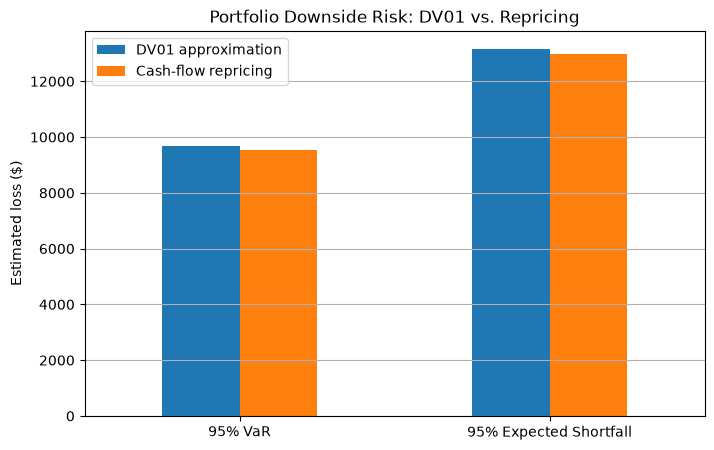

,DV01 approximation,Cash-flow repricing
95% VaR,9666.289254,9553.814327
95% Expected Shortfall,13148.413929,12973.002707


In [46]:
risk_comparison = pd.DataFrame(
    {
        "DV01 approximation": [var_95, expected_shortfall_95],
        "Cash-flow repricing": [repriced_var_95, repriced_es_95],
    },
    index=["95% VaR", "95% Expected Shortfall"]
)

risk_comparison.plot(
    kind="bar",
    figsize=(8, 5),
    title="Portfolio Downside Risk: DV01 vs. Repricing"
)

plt.ylabel("Estimated loss ($)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

risk_comparison

In [47]:
final_summary = pd.DataFrame({
    "Metric": [
        "Hypothetical portfolio value",
        "Historical observations",
        "Daily P&L standard deviation (DV01)",
        "95% VaR (DV01)",
        "95% VaR (repricing)",
        "95% Expected Shortfall (DV01)",
        "95% Expected Shortfall (repricing)",
        "Average absolute P&L difference",
        "Correlation between P&L methods"
    ],
    "Result": [
        "$1,000,000",
        f"{len(comparison):,}",
        f"${daily_pnl.std():,.2f}",
        f"${var_95:,.2f}",
        f"${repriced_var_95:,.2f}",
        f"${expected_shortfall_95:,.2f}",
        f"${repriced_es_95:,.2f}",
        f"${comparison['difference'].abs().mean():,.2f}",
        f"{comparison['portfolio_pnl'].corr(comparison['repriced_portfolio_pnl']):.4f}"
    ]
})

final_summary

,Metric,Result
0,Hypothetical portfolio value,"$1,000,000"
1,Historical observations,"1,499"
2,Daily P&L standard deviation (DV01),"$6,068.41"
3,95% VaR (DV01),"$9,666.29"
4,95% VaR (repricing),"$9,553.81"
5,95% Expected Shortfall (DV01),"$13,148.41"
6,95% Expected Shortfall (repricing),"$12,973.00"
7,Average absolute P&L difference,$35.74
8,Correlation between P&L methods,0.9999


## 4. Key Findings and Limitations

### Key Findings

- Treasury yields showed substantial movements across maturities during the 2020–2025 observation period.
- The hypothetical $1 million portfolio had an estimated DV01 of approximately $1,066.88 per basis point.
- DV01-based historical 95% VaR was approximately $9,666, while cash-flow repricing produced an estimate of approximately $9,554.
- DV01-based 95% Expected Shortfall was approximately $13,148, compared with approximately $12,973 using cash-flow repricing.
- The two P&L estimation methods had a correlation of 0.9999 across the historical scenarios.

### Limitations

- The portfolio is hypothetical and does not represent actual holdings or trading activity.
- Treasury par yields are used as simplified yield proxies for hypothetical bond valuation; they are not actual prices or bond-specific yields.
- DV01-based P&L is a linear approximation. Cash-flow repricing captures nonlinear price sensitivity under the chosen yield assumptions, but it is not a fully market-calibrated valuation.
- Historical VaR and Expected Shortfall depend on the observed sample and do not guarantee future losses will remain within the estimated thresholds.

### Conclusion

This project demonstrates a Python-based workflow for analyzing Treasury yield movements, estimating fixed-income interest-rate sensitivity, and comparing historical downside-risk measures using DV01 approximation and cash-flow repricing.